In [22]:
import numpy as np
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from threadpoolctl import threadpool_limits
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from utils import load_data





## Model 1: Polynomial Regression

In [23]:
print("=== MODEL 1: POLYNOMIAL (DEG=2) LOGISTIC REGRESSION ===")
poly_acc = []
for key in ['20', '30', '40', '40-adapt']:
    _, _, X_train, X_val, y_train, y_val = load_data(key)
    sub_idx = np.random.RandomState(42).choice(len(X_train), min(len(X_train), 12000), replace=False)

    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        LogisticRegression(max_iter=300)
    )
    model.fit(X_train[sub_idx], y_train[sub_idx])
    acc = accuracy_score(y_val, model.predict(X_val))
    poly_acc.append(acc)
    print(f"  Kryptonite-{key:8s} | Val Accuracy: {acc*100:.2f}%")

=== MODEL 1: POLYNOMIAL (DEG=2) LOGISTIC REGRESSION ===
  Kryptonite-20       | Val Accuracy: 55.96%
  Kryptonite-30       | Val Accuracy: 51.85%
  Kryptonite-40       | Val Accuracy: 50.97%
  Kryptonite-40-adapt | Val Accuracy: 51.88%


## Model 2: RBF Kernel SVM

In [24]:
print("=== MODEL 2: RBF KERNEL SVM ===")
rbf_acc = []
for key in ['20', '30', '40', '40-adapt']:
    _, _, X_train, X_val, y_train, y_val = load_data(key)
    sub_idx = np.random.RandomState(42).choice(len(X_train), min(len(X_train), 12000), replace=False)

    model = make_pipeline(
        StandardScaler(),
        SVC(kernel='rbf', C=10.0, gamma='scale')
    )
    model.fit(X_train[sub_idx], y_train[sub_idx])
    acc = accuracy_score(y_val, model.predict(X_val))
    rbf_acc.append(acc)
    print(f"  Kryptonite-{key:8s} | Val Accuracy: {acc*100:.2f}%")


=== MODEL 2: RBF KERNEL SVM ===
  Kryptonite-20       | Val Accuracy: 58.04%
  Kryptonite-30       | Val Accuracy: 55.00%
  Kryptonite-40       | Val Accuracy: 52.16%
  Kryptonite-40-adapt | Val Accuracy: 51.12%


## Model 3: Extra Trees

In [25]:
print("=== MODEL 3: EXTRA TREES CLASSIFIER ===")
extra_acc = []
for key in ['20', '30', '40', '40-adapt']:
    _, _, X_train, X_val, y_train, y_val = load_data(key)

    model = ExtraTreesClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    acc = accuracy_score(y_val, model.predict(X_val))
    extra_acc.append(acc)
    print(f"  Kryptonite-{key:8s} | Val Accuracy: {acc*100:.2f}%")

=== MODEL 3: EXTRA TREES CLASSIFIER ===
  Kryptonite-20       | Val Accuracy: 60.46%
  Kryptonite-30       | Val Accuracy: 58.55%
  Kryptonite-40       | Val Accuracy: 54.28%
  Kryptonite-40-adapt | Val Accuracy: 50.50%


## Model 4: Histogram-Based Gradient Boosted Decision Trees

In [26]:
print("=== MODEL 4: HISTOGRAM GRADIENT BOOSTING ===")
hist_acc = []
for key in ['20', '30', '40', '40-adapt']:
    _, _, X_train, X_val, y_train, y_val = load_data(key)

    model = HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=63, random_state=42
    )
    model.fit(X_train, y_train)
    acc = accuracy_score(y_val, model.predict(X_val))
    hist_acc.append(acc)
    print(f"  Kryptonite-{key:8s} | Val Accuracy: {acc*100:.2f}%")

=== MODEL 4: HISTOGRAM GRADIENT BOOSTING ===
  Kryptonite-20       | Val Accuracy: 58.08%
  Kryptonite-30       | Val Accuracy: 52.85%
  Kryptonite-40       | Val Accuracy: 52.62%
  Kryptonite-40-adapt | Val Accuracy: 49.00%


## Model 5: Scaled MLP

In [27]:
DATASET_KEYS = ("20", "30", "40", "40-adapt")
SPLIT_SEEDS = (42, 123, 2026)
HIDDEN_LAYER_SIZES = (512, 256, 128)
ALPHA = 0.0001
LEARNING_RATE_INIT = 0.001


def build_model(
    seed,
    *,
    max_iter=400,
    early_stopping=True,
    n_iter_no_change=20,
    tol=0.0001,
):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=HIDDEN_LAYER_SIZES,
            max_iter=max_iter,
            early_stopping=early_stopping,
            n_iter_no_change=n_iter_no_change,
            tol=tol,
            alpha=ALPHA,
            learning_rate_init=LEARNING_RATE_INIT,
            random_state=seed,
        ),
    )


print("=== MODEL 5: TUNED SCALED MLP (REPEATED STRATIFIED SPLITS) ===")
mlp_acc = []
with threadpool_limits(limits=1):
    for key in DATASET_KEYS:
        accuracies = []
        epochs = []
        for seed in SPLIT_SEEDS:
            _, _, X_train, X_val, y_train, y_val = load_data(
                key, random_state=seed
            )
            model = build_model(seed)
            model.fit(X_train, y_train)
            acc = accuracy_score(y_val, model.predict(X_val))
            accuracies.append(acc)
            epochs.append(model[-1].n_iter_)
            print(
                f"  Kryptonite-{key} seed={seed}: "
                f"{acc * 100:.2f}% ({model[-1].n_iter_} epochs)"
            )

        mlp_acc.append(np.mean(accuracies))
        print(
            f"  Kryptonite-{key} mean: "
            f"{np.mean(accuracies) * 100:.2f}% "
            f"+/- {np.std(accuracies, ddof=1) * 100:.2f}% "
            f"(sample SD; mean epochs={np.mean(epochs):.1f})"
        )

=== MODEL 5: TUNED SCALED MLP (REPEATED STRATIFIED SPLITS) ===
  Kryptonite-20 seed=42: 91.54% (49 epochs)
  Kryptonite-20 seed=123: 91.54% (62 epochs)
  Kryptonite-20 seed=2026: 92.08% (41 epochs)
  Kryptonite-20 mean: 91.72% +/- 0.31% (sample SD; mean epochs=50.7)
  Kryptonite-30 seed=42: 92.62% (39 epochs)
  Kryptonite-30 seed=123: 92.38% (41 epochs)
  Kryptonite-30 seed=2026: 90.70% (38 epochs)
  Kryptonite-30 mean: 91.90% +/- 1.05% (sample SD; mean epochs=39.3)
  Kryptonite-40 seed=42: 93.00% (51 epochs)
  Kryptonite-40 seed=123: 93.94% (42 epochs)
  Kryptonite-40 seed=2026: 94.03% (38 epochs)
  Kryptonite-40 mean: 93.66% +/- 0.57% (sample SD; mean epochs=43.7)
  Kryptonite-40-adapt seed=42: 50.00% (29 epochs)
  Kryptonite-40-adapt seed=123: 52.25% (50 epochs)
  Kryptonite-40-adapt seed=2026: 47.62% (26 epochs)
  Kryptonite-40-adapt mean: 49.96% +/- 2.31% (sample SD; mean epochs=35.0)


## Plot the Results for Analysis

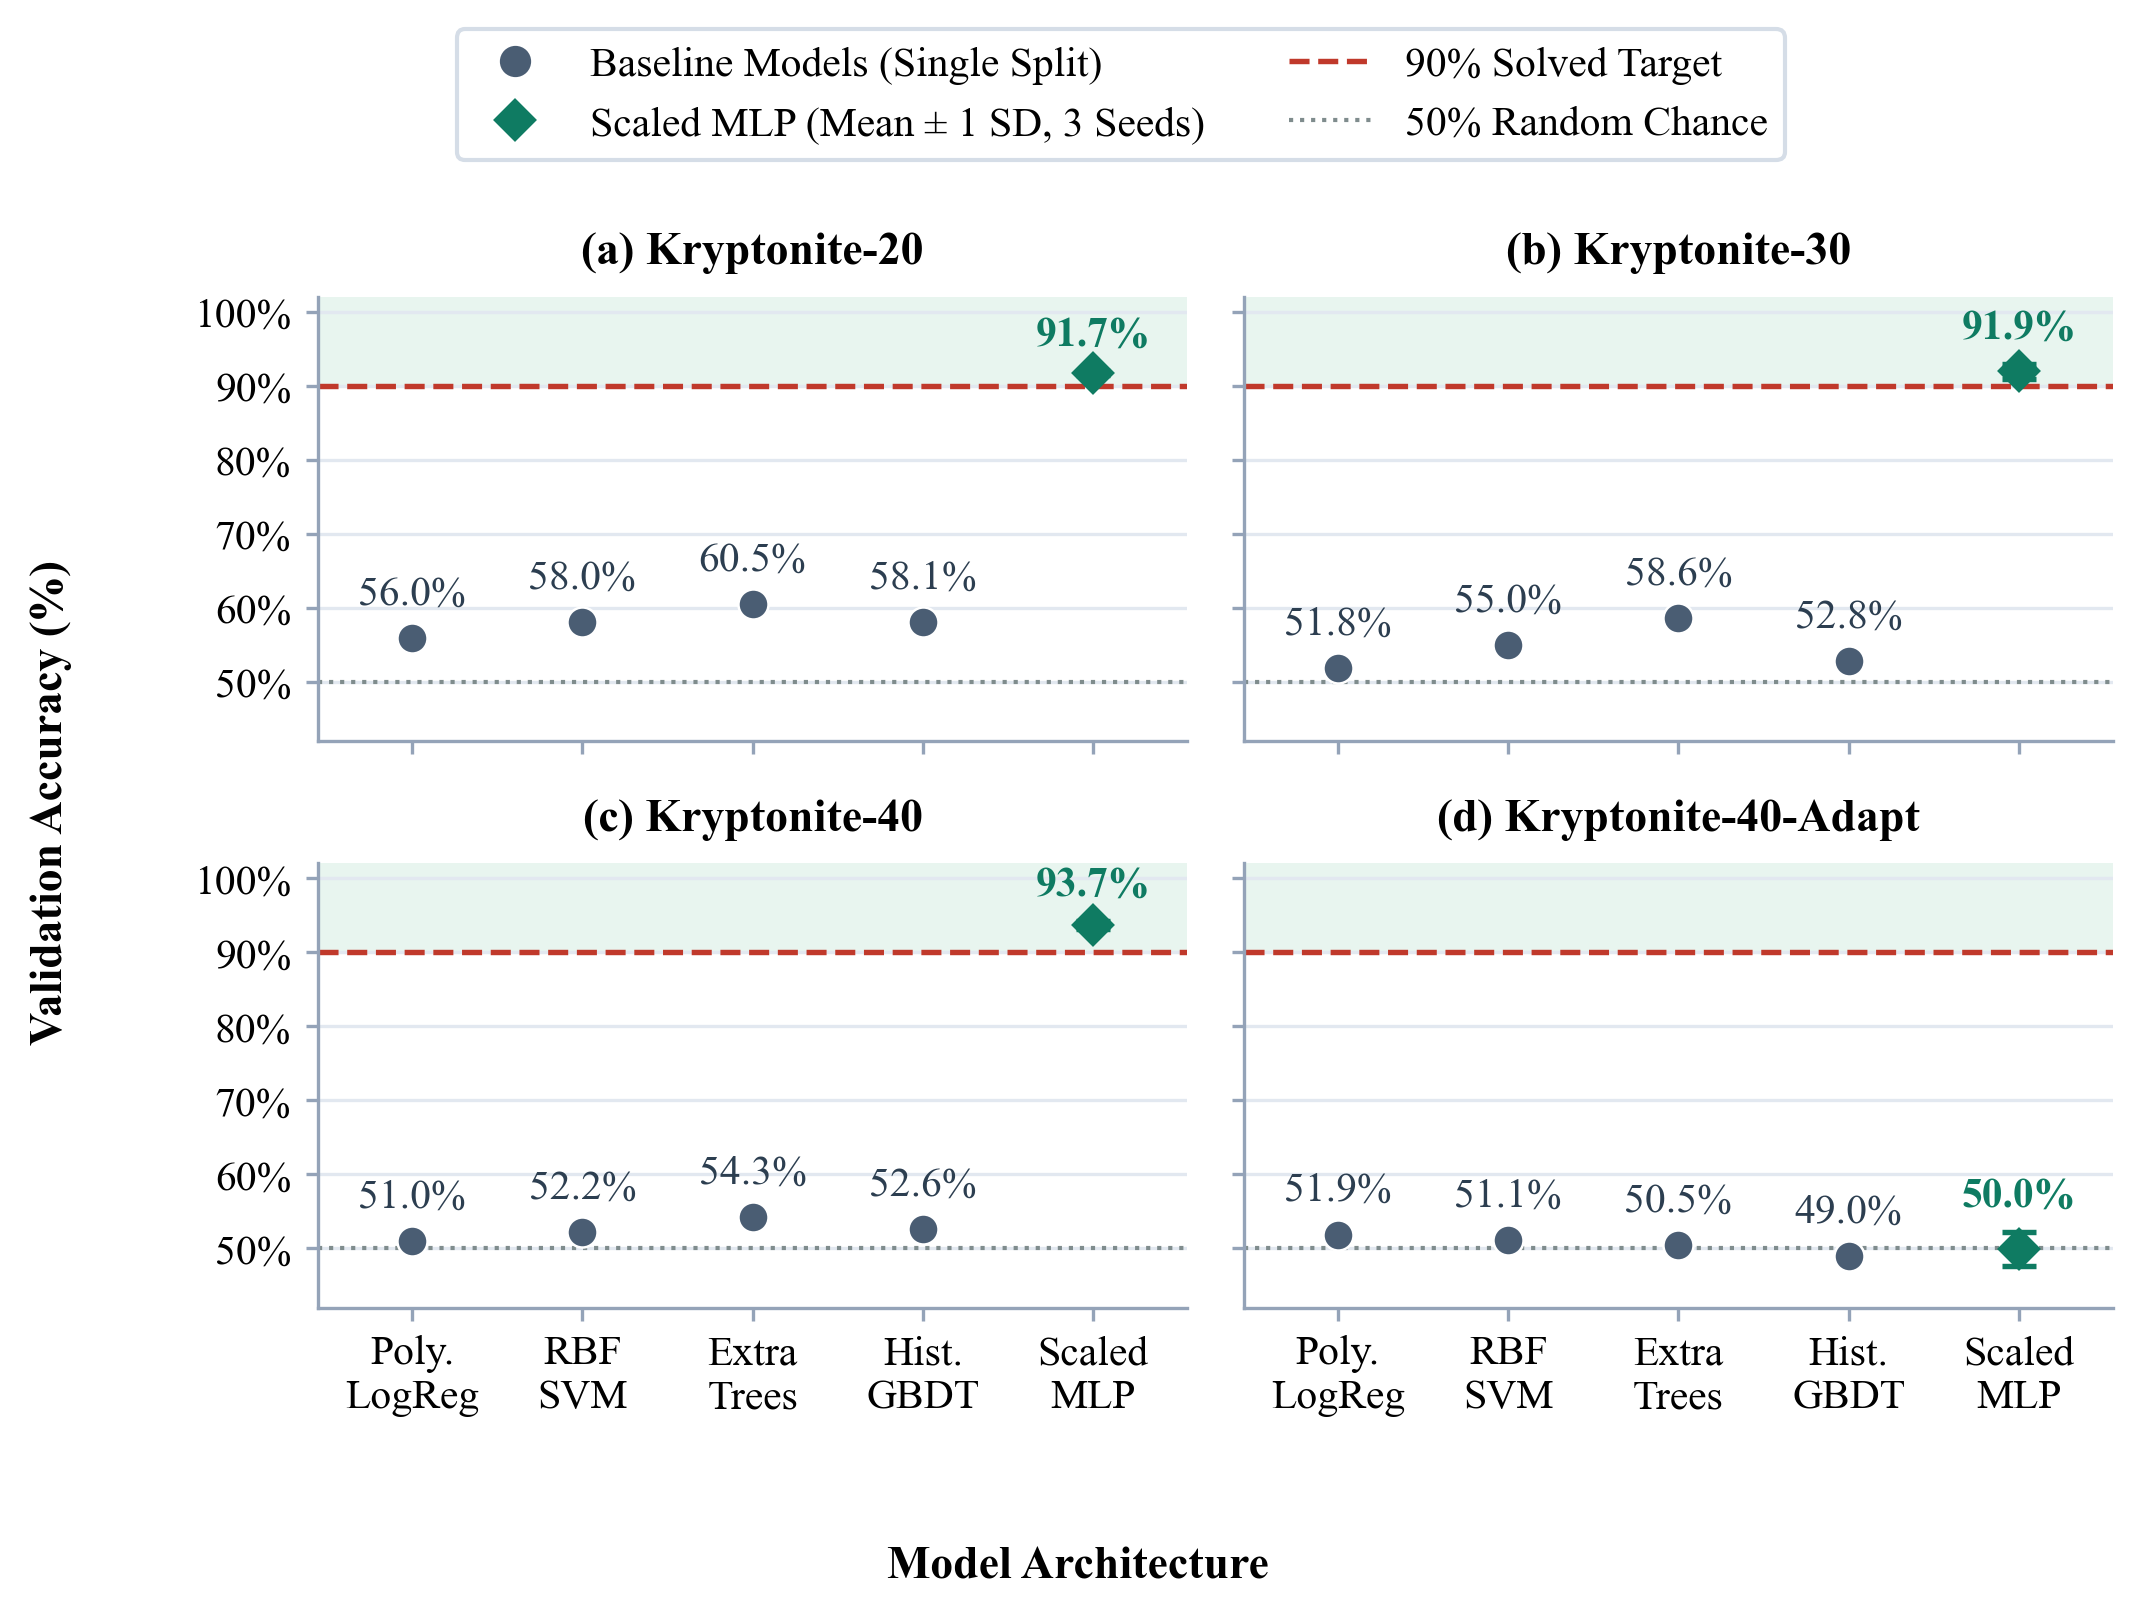

In [28]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Configure publication-grade typography (matches ICML 10pt body text)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 300,
    "savefig.dpi": 300,
})

model_names = [
    "Poly.\nLogReg",
    "RBF\nSVM",
    "Extra\nTrees",
    "Hist.\nGBDT",
    "Scaled\nMLP",
]

# Validation accuracies (%) and sample SD across 3 stratified splits
results = {
    "20": {"accuracy": [poly_acc[0], rbf_acc[0], extra_acc[0], hist_acc[0], mlp_acc[0]], "mlp_std": 0.31},
    "30": {"accuracy": [poly_acc[1], rbf_acc[1], extra_acc[1], hist_acc[1], mlp_acc[1]], "mlp_std": 1.05},
    "40": {"accuracy": [poly_acc[2], rbf_acc[2], extra_acc[2], hist_acc[2], mlp_acc[2]], "mlp_std": 0.57},
    "40-adapt": {"accuracy": [poly_acc[3], rbf_acc[3], extra_acc[3], hist_acc[3], mlp_acc[3]], "mlp_std": 2.31},
}
for res in results.values():
    res["accuracy"] = [acc * 100 for acc in res["accuracy"]]

panel_labels = ("(a) Kryptonite-20", "(b) Kryptonite-30", "(c) Kryptonite-40", "(d) Kryptonite-40-Adapt")

BASELINE_COLOR = "#4A5D73"
MLP_COLOR = "#0F7B62"
TARGET_COLOR = "#C0392B"
CHANCE_COLOR = "#7F8C8D"

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4), sharey=True, sharex=True)
axes = axes.flatten()
positions = np.arange(len(model_names))
mlp_index = model_names.index("Scaled\nMLP")

for ax, (dataset_key, res), title in zip(axes, results.items(), panel_labels):
    accuracies = res["accuracy"]
    mlp_std = res["mlp_std"]

    # Highlight solved region (>= 90% target) and reference baselines
    ax.axhspan(90, 102, color="#E8F5EF", zorder=0)
    ax.axhline(90, color=TARGET_COLOR, linestyle="--", linewidth=1.3, zorder=1)
    ax.axhline(50, color=CHANCE_COLOR, linestyle=":", linewidth=1.0, zorder=1)

    for i, acc in enumerate(accuracies):
        if i == mlp_index:
            ax.errorbar(
                i,
                acc,
                yerr=mlp_std,
                fmt="D",
                color=MLP_COLOR,
                ecolor=MLP_COLOR,
                markersize=6.5,
                capsize=4,
                elinewidth=1.5,
                capthick=1.3,
                zorder=4,
            )
            # Place text cleanly above the upper SD cap
            y_text = acc + mlp_std
            ax.annotate(
                f"{acc:.1f}%",
                (i, y_text),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=10,
                fontweight="bold",
                color=MLP_COLOR,
            )
        else:
            ax.scatter(
                i,
                acc,
                color=BASELINE_COLOR,
                edgecolor="white",
                linewidth=0.6,
                s=52,
                zorder=3,
            )
            ax.annotate(
                f"{acc:.1f}%",
                (i, acc),
                xytext=(0, 6),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=10,
                color="#2C3E50",
            )

    ax.set_title(title, fontweight="bold", pad=8)
    ax.set_xticks(positions)
    ax.set_xticklabels(model_names)
    ax.set_xlim(-0.55, len(model_names) - 0.45)
    ax.set_ylim(42, 102)
    ax.set_yticks(np.arange(50, 101, 10))
    ax.set_yticklabels([f"{v}%" for v in range(50, 101, 10)])

    # Clean publication grid and spines
    ax.grid(axis="y", color="#E2E8F0", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#94A3B8")
    ax.spines["bottom"].set_color("#94A3B8")
    ax.tick_params(axis="both", length=3, color="#94A3B8")

# Shared outer axis labels
fig.supylabel("Validation Accuracy (%)", fontsize=11, fontweight="bold", x=0.015)
fig.supxlabel("Model Architecture", fontsize=11, fontweight="bold", y=0.015)

# Top unified legend
legend_handles = [
    Line2D([], [], marker="o", linestyle="none", color=BASELINE_COLOR, markersize=6.5, label="Baseline Models (Single Split)"),
    Line2D([], [], marker="D", linestyle="none", color=MLP_COLOR, markersize=6.5, label="Scaled MLP (Mean ± 1 SD, 3 Seeds)"),
    Line2D([], [], color=TARGET_COLOR, linestyle="--", linewidth=1.3, label="90% Solved Target"),
    Line2D([], [], color=CHANCE_COLOR, linestyle=":", linewidth=1.0, label="50% Random Chance"),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.52, 0.99),
    ncol=2,
    frameon=True,
    facecolor="white",
    edgecolor="#CBD5E1",
)

fig.tight_layout(rect=(0.03, 0.04, 1.0, 0.88))
plt.show()

## Generate Hidden Labels for Kryptonite-n
Idenitfies the best MLP model respectively and produces the labels for the hidden kryptonite 20, 30, 40 datasets. Saves them to the hiddenlabels directory and checks their format for submission

In [29]:
from pathlib import Path
import joblib
import subprocess
import sys
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

VALIDATION_SEEDS = (42, 123, 2026)
MAX_VALIDATION_EPOCHS = 400
EARLY_STOPPING_PATIENCE = 20
EARLY_STOPPING_TOL = 0.0001
FINAL_SEED = 42

repo_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "check_submission.py").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Could not find check_submission.py in the current directory or its parents")

labels_dir = repo_root / "hiddenlabels"
models_dir = repo_root / "trained_models"
labels_dir.mkdir(exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

best_models = {}
hidden_predictions = {}
with threadpool_limits(limits=1):
    for key in ("20", "30", "40"):
        X = np.load(repo_root / "Datasets" / f"kryptonite-{key}-X.npy")
        y = np.load(repo_root / "Datasets" / f"kryptonite-{key}-y.npy")
        X_hidden = np.load(repo_root / "Datasets" / f"hidden-kryptonite-{key}-X.npy")

        if X.ndim != 2 or y.shape != (X.shape[0],):
            raise ValueError(f"Invalid labeled data shapes for Kryptonite-{key}: X={X.shape}, y={y.shape}")
        if X_hidden.ndim != 2 or X_hidden.shape[1] != X.shape[1]:
            raise ValueError(
                f"Hidden features for Kryptonite-{key} have shape {X_hidden.shape}; "
                f"expected (*, {X.shape[1]})"
            )

        selected_epochs = []
        for seed in VALIDATION_SEEDS:
            X_fit, X_val, y_fit, y_val = train_test_split(
                X, y, test_size=0.1, random_state=seed, stratify=y
            )
            scaler = StandardScaler()
            X_fit = scaler.fit_transform(X_fit)
            X_val = scaler.transform(X_val)
            selector = MLPClassifier(
                hidden_layer_sizes=HIDDEN_LAYER_SIZES,
                alpha=ALPHA,
                learning_rate_init=LEARNING_RATE_INIT,
                max_iter=1,
                early_stopping=False,
                random_state=np.random.RandomState(seed),
                n_iter_no_change=1000,
                tol=0.0,
            )
            best_score = -1.0
            best_epoch = 0
            epochs_without_improvement = 0
            for epoch in range(1, MAX_VALIDATION_EPOCHS + 1):
                classes = np.unique(y_fit) if epoch == 1 else None
                selector.partial_fit(X_fit, y_fit, classes=classes)
                score = accuracy_score(y_val, selector.predict(X_val))
                if score > best_score + EARLY_STOPPING_TOL:
                    best_score = score
                    best_epoch = epoch
                    epochs_without_improvement = 0
                else:
                    epochs_without_improvement += 1
                    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                        break
            if best_epoch == 0:
                raise RuntimeError(f"No validation epoch selected for Kryptonite-{key}, seed={seed}")
            selected_epochs.append(best_epoch)
            print(
                f"Kryptonite-{key}, seed={seed}: best validation epoch {best_epoch}, "
                f"accuracy {best_score:.4f}"
            )

        epochs = int(np.median(selected_epochs))
        print(f"Kryptonite-{key}: refitting all labeled rows for {epochs} epochs")

        # Refit on all labeled examples for the median validation-selected epoch.
        model = build_model(
            FINAL_SEED,
            max_iter=epochs,
            early_stopping=False,
            n_iter_no_change=1000,
            tol=0.0,
        )
        model.fit(X, y)
        predictions = (model.predict_proba(X_hidden)[:, 1] >= 0.5).astype(np.int64)

        if predictions.shape != (X_hidden.shape[0],):
            raise ValueError(
                f"Kryptonite-{key} predictions have shape {predictions.shape}; "
                f"expected ({X_hidden.shape[0]},)"
            )
        if not np.isin(predictions, (0, 1)).all():
            raise ValueError(f"Kryptonite-{key} predictions are not binary labels")

        best_models[key] = model
        hidden_predictions[key] = predictions

for key, model in best_models.items():
    model_path = models_dir / f"tuned_scaled_mlp_{key}.joblib"
    prediction_path = labels_dir / f"y_predicted_{key.replace('-', '_')}.npy"
    joblib.dump(model, model_path)
    np.save(prediction_path, hidden_predictions[key])
    print(
        f"Kryptonite-{key}: trained on all labeled rows; "
        f"saved model to {model_path} and labels to {prediction_path}"
    )

subprocess.run(
    [sys.executable, str(repo_root / "check_submission.py"), str(repo_root)],
    cwd=repo_root,
    check=True,
)

Kryptonite-20, seed=42: best validation epoch 10, accuracy 0.9400
Kryptonite-20, seed=123: best validation epoch 11, accuracy 0.9408
Kryptonite-20, seed=2026: best validation epoch 25, accuracy 0.9333
Kryptonite-20: refitting all labeled rows for 11 epochs


C:\Users\Achira\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (11) reached and the optimization hasn't converged yet.
  warnings.warn(


Kryptonite-30, seed=42: best validation epoch 23, accuracy 0.9335
Kryptonite-30, seed=123: best validation epoch 20, accuracy 0.9415
Kryptonite-30, seed=2026: best validation epoch 42, accuracy 0.9365
Kryptonite-30: refitting all labeled rows for 23 epochs


C:\Users\Achira\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (23) reached and the optimization hasn't converged yet.
  warnings.warn(


Kryptonite-40, seed=42: best validation epoch 20, accuracy 0.9481
Kryptonite-40, seed=123: best validation epoch 6, accuracy 0.9509
Kryptonite-40, seed=2026: best validation epoch 7, accuracy 0.9481
Kryptonite-40: refitting all labeled rows for 7 epochs


C:\Users\Achira\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (7) reached and the optimization hasn't converged yet.
  warnings.warn(


Kryptonite-20: trained on all labeled rows; saved model to c:\Users\Achira\OneDrive\Documents\Uni\Year 4\MML_coursework\trained_models\tuned_scaled_mlp_20.joblib and labels to c:\Users\Achira\OneDrive\Documents\Uni\Year 4\MML_coursework\hiddenlabels\y_predicted_20.npy
Kryptonite-30: trained on all labeled rows; saved model to c:\Users\Achira\OneDrive\Documents\Uni\Year 4\MML_coursework\trained_models\tuned_scaled_mlp_30.joblib and labels to c:\Users\Achira\OneDrive\Documents\Uni\Year 4\MML_coursework\hiddenlabels\y_predicted_30.npy
Kryptonite-40: trained on all labeled rows; saved model to c:\Users\Achira\OneDrive\Documents\Uni\Year 4\MML_coursework\trained_models\tuned_scaled_mlp_40.joblib and labels to c:\Users\Achira\OneDrive\Documents\Uni\Year 4\MML_coursework\hiddenlabels\y_predicted_40.npy


CompletedProcess(args=['C:\\Users\\Achira\\AppData\\Local\\Microsoft\\WindowsApps\\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\\python.exe', 'c:\\Users\\Achira\\OneDrive\\Documents\\Uni\\Year 4\\MML_coursework\\check_submission.py', 'c:\\Users\\Achira\\OneDrive\\Documents\\Uni\\Year 4\\MML_coursework'], returncode=0)

## Showing how increasing data size improves performance

=== SCALING LAW REFUTATION: 25% vs 50% vs 100% TRAINING DATA ===

--- Kryptonite-20 ---
  Frac= 25% (N= 2400) | Poly LogReg: 52.31% ± 1.54% | Scaled MLP: 55.44% ± 2.31%
  Frac= 50% (N= 4800) | Poly LogReg: 53.86% ± 0.95% | Scaled MLP: 67.24% ± 2.87%
  Frac=100% (N= 9600) | Poly LogReg: 55.12% ± 0.73% | Scaled MLP: 91.72% ± 0.31%

--- Kryptonite-30 ---
  Frac= 25% (N= 4000) | Poly LogReg: 51.93% ± 0.51% | Scaled MLP: 51.43% ± 1.23%
  Frac= 50% (N= 8000) | Poly LogReg: 52.72% ± 0.91% | Scaled MLP: 57.98% ± 0.84%
  Frac=100% (N=16000) | Poly LogReg: 52.48% ± 0.75% | Scaled MLP: 91.90% ± 1.05%

--- Kryptonite-40 ---
  Frac= 25% (N= 6400) | Poly LogReg: 51.34% ± 1.10% | Scaled MLP: 52.20% ± 0.57%
  Frac= 50% (N=12800) | Poly LogReg: 52.72% ± 0.67% | Scaled MLP: 58.23% ± 1.14%
  Frac=100% (N=25600) | Poly LogReg: 53.54% ± 0.28% | Scaled MLP: 93.66% ± 0.57%


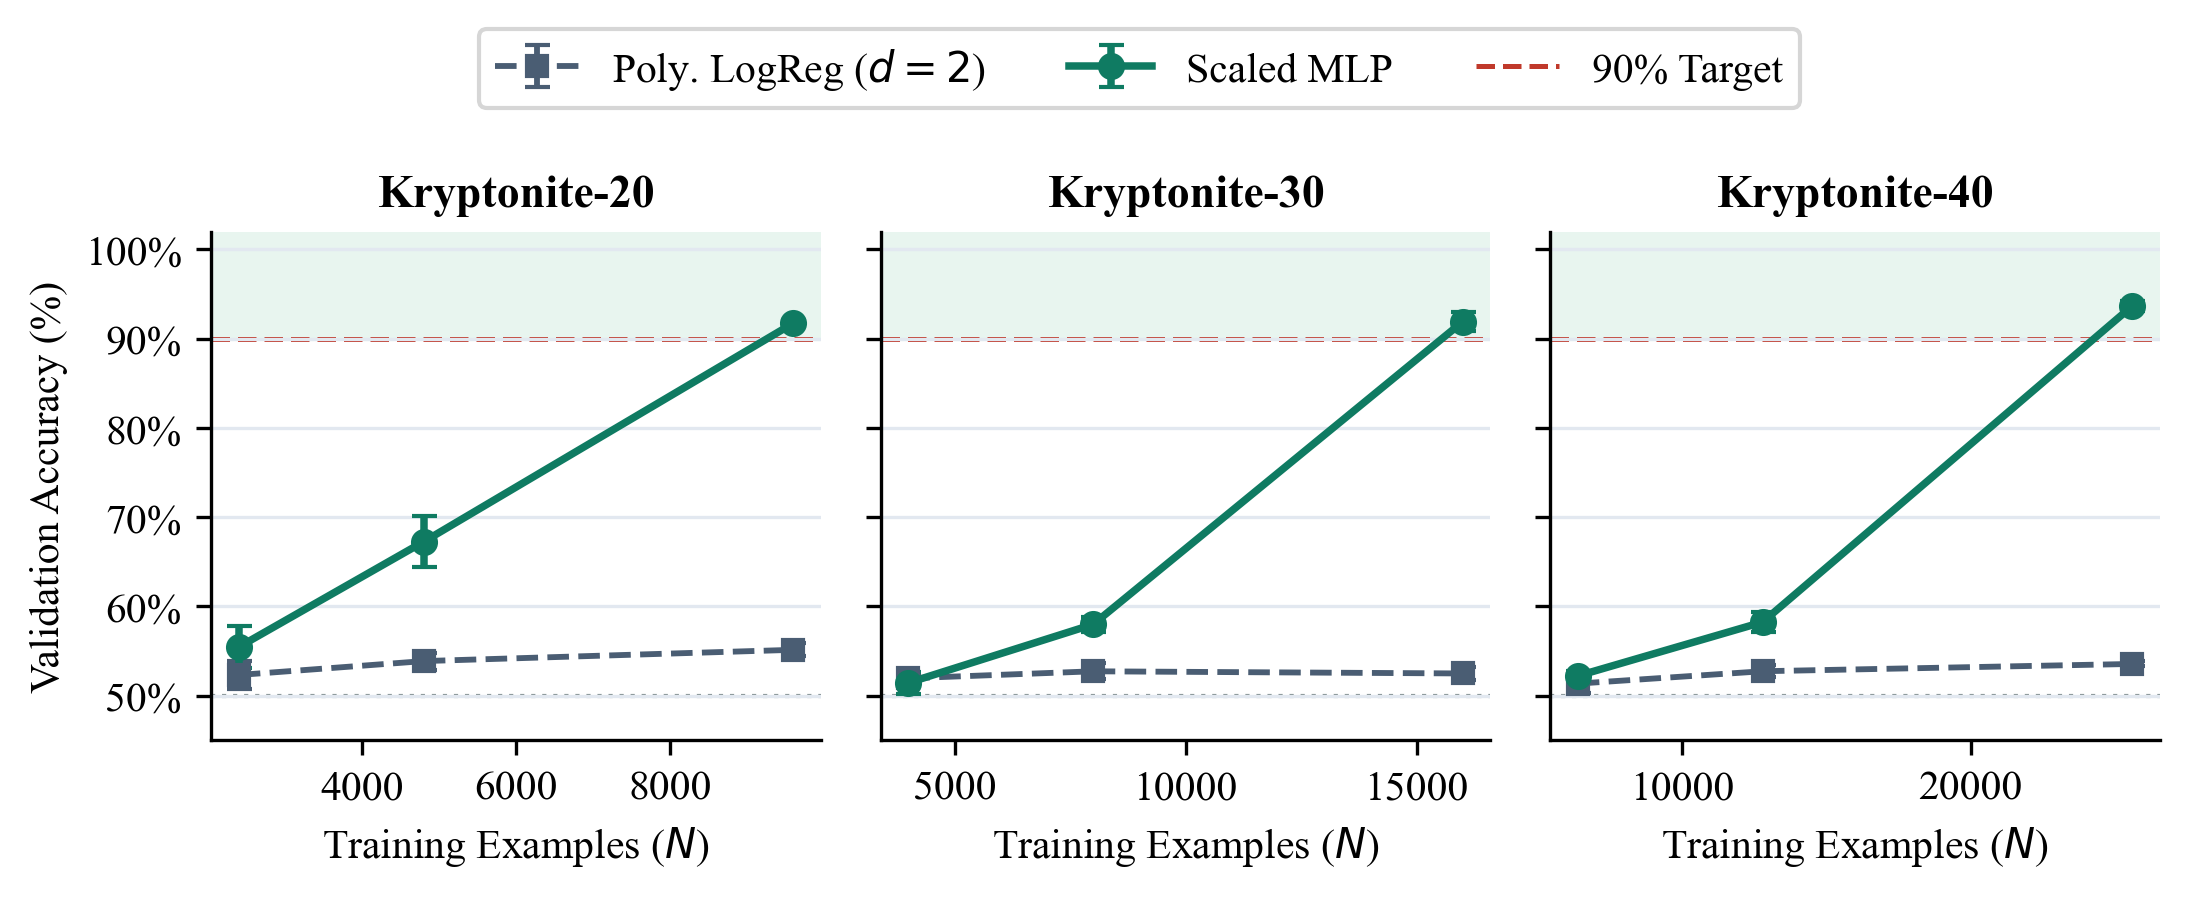

In [30]:
# Publication typography matching ICML 10pt body text
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 300,
    "savefig.dpi": 300,
})

DATASET_KEYS = ("20", "30", "40")
FRACTIONS = (0.25, 0.50, 1.00)
SPLIT_SEEDS = (42, 123, 2026)

def build_poly_logreg():
    return make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        LogisticRegression(C=0.85, max_iter=300),
    )

def build_scaled_mlp(seed):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(512, 256, 128),
            max_iter=400,
            early_stopping=True,
            n_iter_no_change=20,
            tol=1e-4,
            alpha=1e-4,
            learning_rate_init=1e-3,
            random_state=seed,
        ),
    )

def stratified_subset_indices(X_train, y_train, fraction, seed):
    n_sub = int(len(X_train) * fraction)
    if fraction >= 1.0:
        return np.arange(len(X_train))

    sub_idx, _ = train_test_split(
        np.arange(len(X_train)),
        train_size=n_sub,
        random_state=seed,
        stratify=y_train,
    )
    return sub_idx

results = {k: {"sizes": [], "poly_mean": [], "poly_std": [], "mlp_mean": [], "mlp_std": []} for k in DATASET_KEYS}

print("=== SCALING LAW REFUTATION: 25% vs 50% vs 100% TRAINING DATA ===")
with threadpool_limits(limits=1):
    for key in DATASET_KEYS:
        print(f"\n--- Kryptonite-{key} ---")
        for frac in FRACTIONS:
            poly_accs, mlp_accs = [], []
            n_samples = 0

            for seed in SPLIT_SEEDS:
                _, _, X_train, X_val, y_train, y_val = load_data(key, random_state=seed)
                n_sub = int(len(X_train) * frac)
                n_samples = n_sub

                # Stratified subsample of the training split while keeping X_val fixed
                sub_idx = stratified_subset_indices(X_train, y_train, frac, seed)

                # 1. Quadratic Logistic Regression (Prompt Paper Baseline)
                poly = build_poly_logreg()
                poly.fit(X_train[sub_idx], y_train[sub_idx])
                poly_accs.append(accuracy_score(y_val, poly.predict(X_val)) * 100)

                # 2. Standardized MLP
                mlp = build_scaled_mlp(seed)
                mlp.fit(X_train[sub_idx], y_train[sub_idx])
                mlp_accs.append(accuracy_score(y_val, mlp.predict(X_val)) * 100)

            results[key]["sizes"].append(n_samples)
            results[key]["poly_mean"].append(np.mean(poly_accs))
            results[key]["poly_std"].append(np.std(poly_accs, ddof=1))
            results[key]["mlp_mean"].append(np.mean(mlp_accs))
            results[key]["mlp_std"].append(np.std(mlp_accs, ddof=1))

            print(
                f"  Frac={int(frac*100):3d}% (N={n_samples:5d}) | "
                f"Poly LogReg: {np.mean(poly_accs):5.2f}% ± {np.std(poly_accs, ddof=1):4.2f}% | "
                f"Scaled MLP: {np.mean(mlp_accs):5.2f}% ± {np.std(mlp_accs, ddof=1):4.2f}%"
            )

# --- Plot Scaling Curves (1x3 Panel Grid) ---
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.9), sharey=True)
MLP_COLOR = "#0F7B62"
POLY_COLOR = "#4A5D73"
TARGET_COLOR = "#C0392B"

for ax, key in zip(axes, DATASET_KEYS):
    res = results[key]
    ax.axhspan(90, 102, color="#E8F5EF", zorder=0)
    ax.axhline(90, color=TARGET_COLOR, linestyle="--", linewidth=1.2, zorder=1)
    ax.axhline(50, color="#7F8C8D", linestyle=":", linewidth=1.0, zorder=1)

    ax.errorbar(
        res["sizes"], res["poly_mean"], yerr=res["poly_std"],
        fmt="s--", color=POLY_COLOR, markersize=5, capsize=3, linewidth=1.4,
        label="Poly. LogReg ($d=2$)"
    )
    ax.errorbar(
        res["sizes"], res["mlp_mean"], yerr=res["mlp_std"],
        fmt="o-", color=MLP_COLOR, markersize=5.5, capsize=3, linewidth=1.8,
        label="Scaled MLP"
    )

    ax.set_title(f"Kryptonite-{key}", fontweight="bold", pad=6)
    ax.set_xlabel("Training Examples ($N$)")
    ax.set_ylim(45, 102)
    ax.set_yticks(np.arange(50, 101, 10))
    ax.set_yticklabels([f"{v}%" for v in range(50, 101, 10)])
    ax.grid(axis="y", color="#E2E8F0", linewidth=0.8, zorder=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Validation Accuracy (%)")
handles, labels = axes[0].get_legend_handles_labels()
handles.append(plt.Line2D([], [], color=TARGET_COLOR, linestyle="--", linewidth=1.2, label="90% Target"))
fig.legend(handles, labels + ["90% Target"], loc="upper center", bbox_to_anchor=(0.52, 1.04), ncol=3, frameon=True)

fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.90))
plt.show()